# 04: the 480 fps slow-motion clips (forehand, backhand)

Same analysis as `03_video_60fps.ipynb` (skeletons, wrist speed, strokes, per-stroke metrics, consistency), on the slow-motion clips `derechasSM.mp4` (forehand) and `revesSM.mp4` (backhand), realme GT Neo 3, 2026-11-18. Additional questions specific to 480 fps:
1. Are the 480 fps frames real or interpolated, and what does the light look like at a 1/480 s exposure? (section 2)
2. Does the tighter framing lose joints? (section 3)
3. RTMPose with the detector on every frame would take about 1 h for these 8,717 frames. Can the detector run less often without changing the keypoints? (section 4)
4. How much peak speed does 60 fps lose, compared with 480 fps on the same strokes? (section 6)

Inputs: `data/derived/TableTennis1/vids/<clip>_keypoints_<variant>.csv` from `scripts/pose_video.py` (`t_s` already in real time, see section 1). Analysis code shared with notebook 03: `src/pose_tracker/strokes.py`. Results kept: `test-logs/strokes_TableTennis1_480fps_2026-11-18.csv`. Annotated videos: `data/derived/TableTennis1/vids/<clip>_annotated.mp4`.

In [1]:
import csv, subprocess
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pose_tracker.stills import ROOT, COCO, MP_TO_COCO, EDGES, torso_px
from pose_tracker.video import frame_times, real_frame_times, capture_fps, iter_frames, read_keypoints
from pose_tracker.strokes import SH, EL, WR, speed, elbow_series, detect_strokes, stroke_metrics

VIDS = ROOT / "data/TableTennis1/vids"
DER = ROOT / "data/derived/TableTennis1/vids"
LOG = ROOT / "test-logs"
DATE = "2026-11-18"
CLIPS = {"derechasSM": "forehand", "revesSM": "backhand"}
COL = {"mediapipe": "tab:orange", "rtmpose": "tab:blue"}

## 1. Files and real time
From the ffprobe log written by notebook 03. The slow-motion files are 480 fps captures written as 29.97 fps files, so the file timeline is 16x stretched. `real_frame_times` rescales the container timestamps so that the median spacing equals 1/480 s. The phone writes perfectly even timestamps into these files, so any real capture jitter cannot be seen; the 1/480 s spacing is **[assumed]** from the capture tag (section 2 supports it).

In [2]:
print("".join(l for l in open(LOG / f"ffprobe_TableTennis1_vids_{DATE}.txt") if "SM" in l))
T = {}
for c in CLIPS:
    tf, T[c] = frame_times(VIDS / f"{c}.mp4"), real_frame_times(VIDS / f"{c}.mp4")
    d = 1000 * np.diff(T[c])
    print(f"{c:<11} capture {capture_fps(VIDS / f'{c}.mp4'):.0f} fps | file dt {1000*np.median(np.diff(tf)):.2f} ms -> "
          f"real dt median {np.median(d):.3f} ms (min {d.min():.3f}, max {d.max():.3f}) | {len(T[c])} frames = {T[c][-1]:.2f} s real")

derechasSM.mp4   h264 1280x720 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  29.97, capture fps   480 | 5661 frames, file  188.9 s, real 11.79 s
revesSM.mp4      h264 1280x720 rot  -90 yuvj420p range=pc matrix=bt470bg transfer=bt709 | file fps  29.97, capture fps   480 | 3056 frames, file  102.0 s, real  6.37 s



derechasSM  capture 480 fps | file dt 33.37 ms -> real dt median 2.083 ms (min 2.075, max 2.090) | 5661 frames = 11.79 s real


revesSM     capture 480 fps | file dt 33.37 ms -> real dt median 2.083 ms (min 2.075, max 2.090) | 3056 frames = 6.36 s real


## 2. Are the frames real 480 fps? What does the light do?
Mean brightness of a patch of plain wall (top left) for the first 400 frames, compared with the 60 fps backhand clip.

revesSM     brightness  209.2, frame-to-frame std 2.13 grey levels, strongest frequency 120.0 Hz, mean by frame phase mod 4: [-2.74, -0.87, 3.03, 0.58] | pixel noise 2.08


derechasSM  brightness  195.3, frame-to-frame std 2.56 grey levels, strongest frequency 120.0 Hz, mean by frame phase mod 4: [3.31, 1.53, -2.78, -2.06] | pixel noise 0.81


reves60     brightness  211.9, frame-to-frame std 0.28 grey levels, strongest frequency   6.8 Hz, mean by frame phase mod 4: [-0.05, -0.05, -0.1, 0.05] | pixel noise 0.68


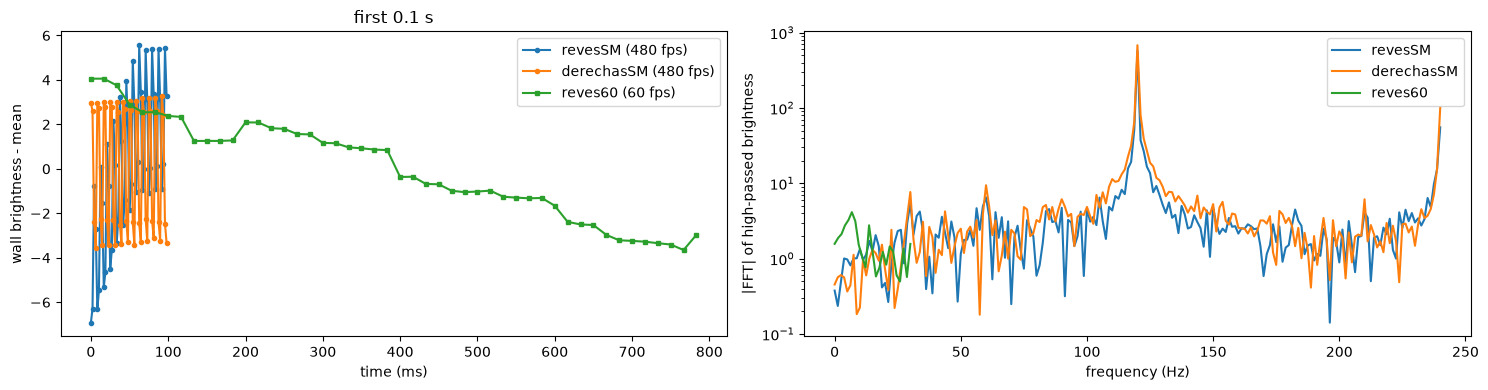

In [3]:
def wall_series(clip, n):
    m, patches = [], []
    for i, im in enumerate(iter_frames(VIDS / f"{clip}.mp4")):
        if i >= n: break
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32); H, W = g.shape
        p = g[int(.05*H):int(.12*H), int(.05*W):int(.25*W)]
        m.append(p.mean()); patches.append(p - p.mean())
    return np.array(m), np.array(patches)

fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for clip, fps in [("revesSM", 480), ("derechasSM", 480), ("reves60", 60)]:
    m, patches = wall_series(clip, 400 if fps == 480 else 60)
    hp = m - np.convolve(m, np.ones(9) / 9, "same"); hp = hp[8:-8]
    spec = np.abs(np.fft.rfft(hp)); f = np.fft.rfftfreq(len(hp), 1 / fps)
    noise = patches.std(axis=0).mean()  # temporal std per pixel after removing each frame's mean (flicker)
    print(f"{clip:<11} brightness {m.mean():6.1f}, frame-to-frame std {hp.std():.2f} grey levels, strongest frequency {f[spec.argmax()]:5.1f} Hz, "
          f"mean by frame phase mod 4: {[round(float(hp[k::4].mean()), 2) for k in range(4)]} | pixel noise {noise:.2f}")
    tt = np.arange(len(m[:48])) / fps * 1000
    axs[0].plot(tt, m[:48] - m[:48].mean(), "o-" if fps == 480 else "s-", ms=3, label=f"{clip} ({fps} fps)")
    axs[1].semilogy(f, spec + 1e-3, label=clip)
axs[0].set_xlabel("time (ms)"); axs[0].set_ylabel("wall brightness - mean"); axs[0].legend(); axs[0].set_title("first 0.1 s")
axs[1].set_xlabel("frequency (Hz)"); axs[1].set_ylabel("|FFT| of high-passed brightness"); axs[1].legend()
plt.tight_layout(); plt.show()

**Reading this:**
- The 480 fps clips **flicker at exactly 120 Hz**: the wall brightness repeats every 4 frames, with a swing of several grey levels around about 200. That is the room light, which flickers at twice the 60 Hz mains frequency. The 60 fps clip shows no flicker: a 1/60 s exposure integrates two full flicker cycles, while a 1/480 s exposure catches a quarter cycle.
- **This is evidence that the 480 fps capture is real**, not interpolated from a lower rate [verified as far as this test goes]. Interpolated from 120 fps, every real frame would fall on the same flicker phase, the flicker would vanish, and the in-between frames would be blends. Interpolated from 240 fps, phases 1 and 3 would be averages of their neighbours. The four phase means above are four independent levels, so the sensor sampled the light at four distinct moments per cycle.
- Pixel noise (temporal, after removing the flicker) is higher at 480 fps, as expected from the shorter exposure. The 720p frames are downscaled sensor output, which hides part of it.
- Consequences: (a) any method that uses brightness or colour thresholds (the paddle colour mask, frame differencing) sees a 4-frame pattern and must normalize brightness per frame; (b) the pose models are not visibly affected (section 4 checks the keypoints for a 120 Hz component).

## 3. Keypoints, and the tighter framing
Variants on disk: MediaPipe (VIDEO mode, every frame); RTMPose with the person detector on every frame (`rtmpose`, backhand only, the slow reference); detector every 8 frames (`rtmpose_det8`: same 16.7 ms detection interval as at 60 fps); detector on the first frame only, after which the box always follows the previous skeleton (`rtmpose_track`). Speeds in ms per frame are from `test-logs/pose-speed_<date>.csv`.

In [4]:
K = {}
for p in sorted(DER.glob("*SM_keypoints_*.csv")):
    clip, var = p.stem.split("_keypoints_")
    t, xy, conf, joints = read_keypoints(p)
    assert np.allclose(t, T[clip], atol=1e-5)
    if var == "mediapipe":
        xy, conf = xy[:, MP_TO_COCO], conf[:, MP_TO_COCO]
    K[clip, var] = dict(t=t, xy=xy, conf=conf, torso=float(np.nanmedian([torso_px(f) for f in xy])))
print("frames without a person:", {f"{c}/{v}": int(np.isnan(k["xy"][:, 0, 0]).sum()) for (c, v), k in K.items()}, "of", {c: len(T[c]) for c in CLIPS})
print("".join(l for l in open(LOG / f"pose-speed_{DATE}.csv") if "SM" in l or l.startswith("clip")))

frames without a person: {'derechasSM/mediapipe': 1309, 'derechasSM/rtmpose_det8': 0, 'derechasSM/rtmpose_track': 0, 'revesSM/mediapipe': 0, 'revesSM/rtmpose': 0, 'revesSM/rtmpose_det8': 0, 'revesSM/rtmpose_track': 0} of {'derechasSM': 5661, 'revesSM': 3056}
clip,model,frames,total_s,median_ms,min_ms,median_ms_excl_first
revesSM.mp4,mediapipe,3056,64.3,19.6,17.4,19.6
derechasSM.mp4,mediapipe,5661,121.6,20.3,12.8,20.3
revesSM.mp4,rtmpose_track,3056,86.7,24.5,14.0,24.5
derechasSM.mp4,rtmpose_track,5661,175.2,29.1,19.6,29.1
revesSM.mp4,rtmpose_det8,3056,216.9,26.1,15.4,26.1
derechasSM.mp4,rtmpose_det8,5661,460.1,27.6,20.1,27.6
revesSM.mp4,rtmpose,3056,1156.8,368.4,308.4,368.4



Fraction of frames in which a joint lies outside the image, or within 2 % of the image height from the edge (the models still output a position there: an extrapolation). The sample frames below show why the forehand numbers are so high.

In [5]:
H, W = 1280, 720
print(f"{'clip':<11} {'variant':<14} " + " ".join(f"{j[:7]:>7}" for j in COCO))
for (c, v), k in K.items():
    x, y = k["xy"][..., 0], k["xy"][..., 1]
    out = (x < 0.02 * H) | (x > W - 0.02 * H) | (y < 0.02 * H) | (y > H - 0.02 * H)
    print(f"{c:<11} {v:<14} " + " ".join(f"{100*out[:, j].mean():6.0f}%" for j in range(17)))

clip        variant           nose   l_eye   r_eye   l_ear   r_ear l_shoul r_shoul l_elbow r_elbow l_wrist r_wrist   l_hip   r_hip  l_knee  r_knee l_ankle r_ankle
derechasSM  mediapipe          14%     21%     11%     29%     11%     66%     39%     66%     26%     22%      8%     66%     62%     56%     41%     68%     52%
derechasSM  rtmpose_det8       42%     51%     38%     62%     35%     91%     59%     48%     22%     33%     15%     94%     89%     54%     35%     99%     91%
derechasSM  rtmpose_track      42%     51%     38%     62%     35%     91%     59%     48%     22%     33%     15%     94%     89%     54%     35%     99%     91%
revesSM     mediapipe           0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      1%      0%      0%      0%      0%     62%      0%
revesSM     rtmpose             0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      0%      0%     60%      0%
revesSM     rtmpose_de

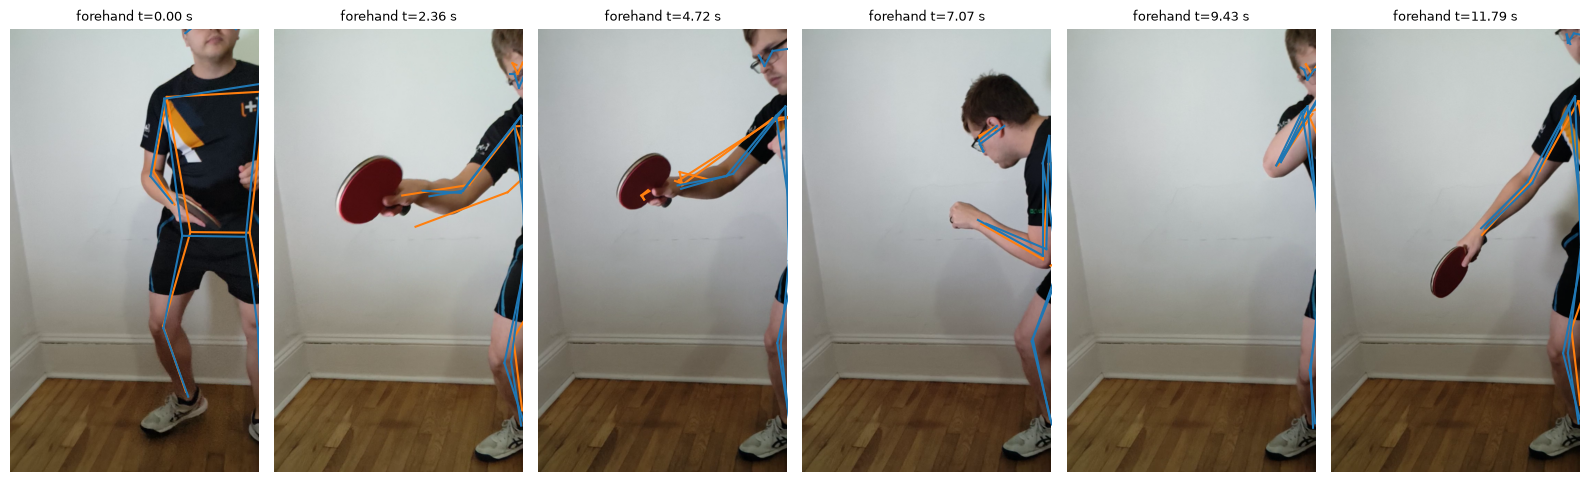

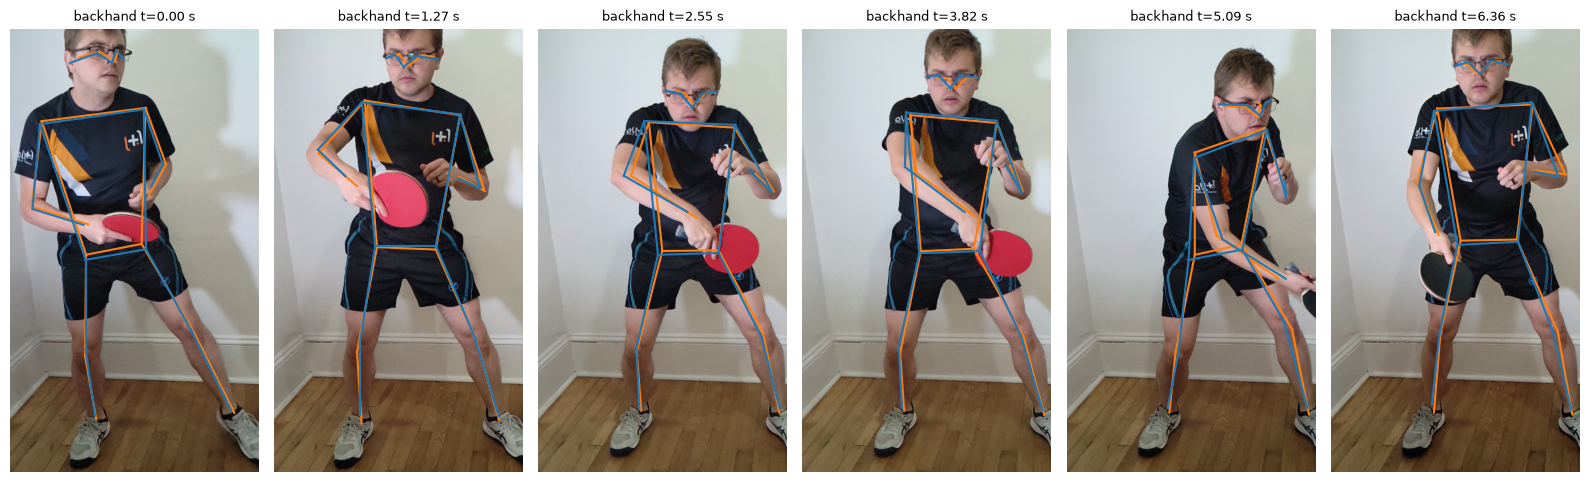

In [6]:
def grab(clip, idx):
    cap = cv2.VideoCapture(str(VIDS / f"{clip}.mp4")); frames = {}
    for i in range(max(idx) + 1):
        ok, fr = cap.read()
        if i in idx: frames[i] = fr
    cap.release(); return frames

def draw(ax, xy, col, lw=1.5):
    for a, b in EDGES:
        ax.plot(*xy[[a, b]].T, color=col, lw=lw)

for c in CLIPS:
    idx = list(np.linspace(0, len(T[c]) - 1, 6).astype(int)); fr = grab(c, idx)
    fig, axs = plt.subplots(1, 6, figsize=(16, 5))
    for ax, i in zip(axs, idx):
        ax.imshow(cv2.cvtColor(fr[i], cv2.COLOR_BGR2RGB)); ax.axis("off")
        draw(ax, K[c, "mediapipe"]["xy"][i], COL["mediapipe"]); draw(ax, K[c, "rtmpose_track"]["xy"][i], COL["rtmpose"])
        ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_title(f"{CLIPS[c]} t={T[c][i]:.2f} s", fontsize=9)
    plt.tight_layout(); plt.show()

**The forehand clip is excluded from the stroke analysis.** You stand at the right edge of the tighter 720p frame: torso, hips and legs are outside the image in most frames (table above), the skeletons collapse onto the frame edge, and MediaPipe loses the person in 1,309 of 5,661 frames (23 %; these losses coincide with the head being higher in the frame, median eye height 80 vs 147 px, but the eyes never leave the frame, so the exact cause is not proven). With the torso out of frame the body scale is wrong, and the forehand wrist speeds come out at 20-48 torso/s, about 3-6x physiological. Its speed curve is still plotted in section 7 as evidence. Sections 5-8 use the backhand.

## 4. RTMPose: how often must the detector run?
Reference: `rtmpose` (detector every frame) on the backhand. For each variant: distance to the reference per frame (median over the 17 joints, and the wrist, in % of torso), and the spectrum of the raw frame-to-frame wrist motion. A detector that runs every 8 frames changes the crop box every 8 frames; at 480 fps that would show as a 60 Hz line. A 120 Hz line would mean the light flicker reaches the keypoints.

rtmpose_det8   vs detector-every-frame: all joints median  0.82 % torso, p95  1.24 %; wrist median  1.09 %, p95  2.93 %
rtmpose_track  vs detector-every-frame: all joints median  0.91 % torso, p95  1.26 %; wrist median  1.22 %, p95  2.98 %
mediapipe      vs detector-every-frame: all joints median  3.34 % torso, p95  4.79 %; wrist median  4.41 %, p95 11.19 %
   rtmpose        wrist jitter spectrum: 60 Hz line   1.4x median, 120 Hz   2.2x
   rtmpose_det8   wrist jitter spectrum: 60 Hz line   0.8x median, 120 Hz   2.5x
   rtmpose_track  wrist jitter spectrum: 60 Hz line   1.0x median, 120 Hz   2.2x
   mediapipe      wrist jitter spectrum: 60 Hz line   1.7x median, 120 Hz   1.6x


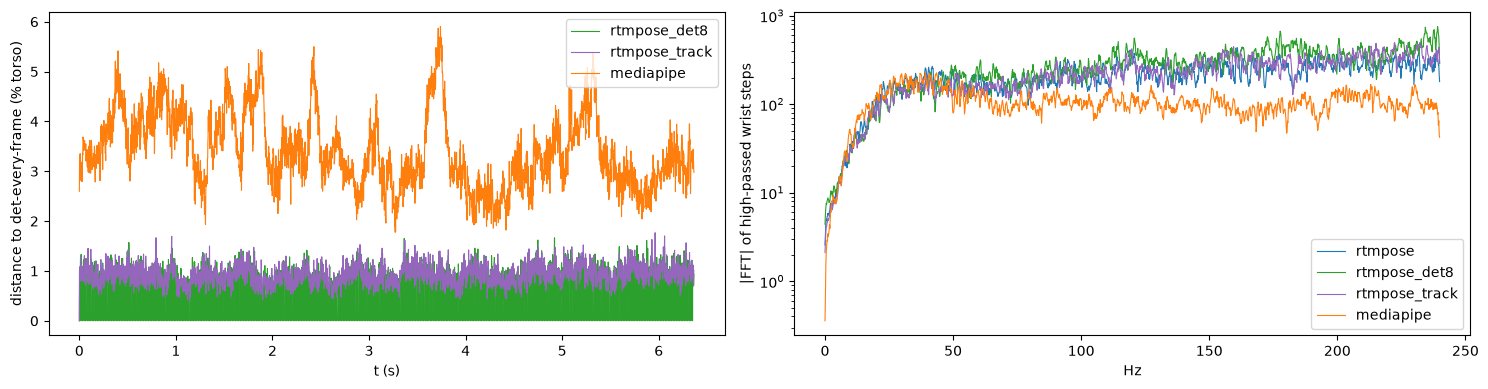

In [7]:
ref = K["revesSM", "rtmpose"]; t = ref["t"]; tor = ref["torso"]
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for v, col in [("rtmpose_det8", "tab:green"), ("rtmpose_track", "tab:purple"), ("mediapipe", "tab:orange")]:
    k = K["revesSM", v]
    d = 100 * np.linalg.norm(k["xy"] - ref["xy"], axis=2) / tor
    print(f"{v:<14} vs detector-every-frame: all joints median {np.median(d):5.2f} % torso, "
          f"p95 {np.percentile(np.median(d, axis=1), 95):5.2f} %; wrist median {np.median(d[:, WR]):5.2f} %, p95 {np.percentile(d[:, WR], 95):5.2f} %")
    axs[0].plot(t, np.median(d, axis=1), color=col, lw=0.8, label=v)
for v, col in [("rtmpose", "tab:blue"), ("rtmpose_det8", "tab:green"), ("rtmpose_track", "tab:purple"), ("mediapipe", "tab:orange")]:
    w = K["revesSM", v]["xy"][:, WR]
    step = np.diff(w, axis=0); step -= np.array([np.convolve(s, np.ones(17) / 17, "same") for s in step.T]).T
    sp = np.abs(np.fft.rfft(step[20:-20], axis=0)).sum(1); f = np.fft.rfftfreq(len(step[20:-20]), 1 / 480)
    axs[1].semilogy(f, np.convolve(sp, np.ones(5) / 5, "same"), color=col, lw=0.8, label=v)
    i60, i120 = np.argmin(abs(f - 60)), np.argmin(abs(f - 120))
    base = np.median(sp[(f > 30) & (f < 230)])
    print(f"   {v:<14} wrist jitter spectrum: 60 Hz line {sp[i60-1:i60+2].max()/base:5.1f}x median, 120 Hz {sp[i120-1:i120+2].max()/base:5.1f}x")
axs[0].set_xlabel("t (s)"); axs[0].set_ylabel("distance to det-every-frame (% torso)"); axs[0].legend()
axs[1].set_xlabel("Hz"); axs[1].set_ylabel("|FFT| of high-passed wrist steps"); axs[1].legend()
plt.tight_layout(); plt.show()

**Choice: `rtmpose_track` (detector on the first frame only).** All three schedules agree with detector-every-frame to within about 1 % of torso length (median; 95th percentile 1.2-1.3 %, wrist about 3 %). That is far below the 3-4 % gap between the two models. There is no 60 Hz line from the every-8-frames box switch: the 3-5 px jumps seen in a first smoke test are within the jitter. Cost (mean = total / frames, from the speed log): detector every frame 379 ms, every 8 frames 71-81 ms, first frame only 28-31 ms, MediaPipe 21 ms per frame. This works because there is one person and the box never loses them; with someone walking through the frame, or a lost person, it would need a periodic or triggered re-detection.

All variants show a weak 120 Hz component in the wrist motion (about 2x the spectral median): the light flicker reaches the keypoints a little. The 52 ms smoothing chosen below averages about 6 flicker cycles, which removes it.

## 5. Wrist speed at 480 fps: how much smoothing?
Same approach as notebook 03, now with 8x more samples per stroke. Windows in frames and ms; the 73-frame window (152 ms) equals the 9-frame window used at 60 fps.

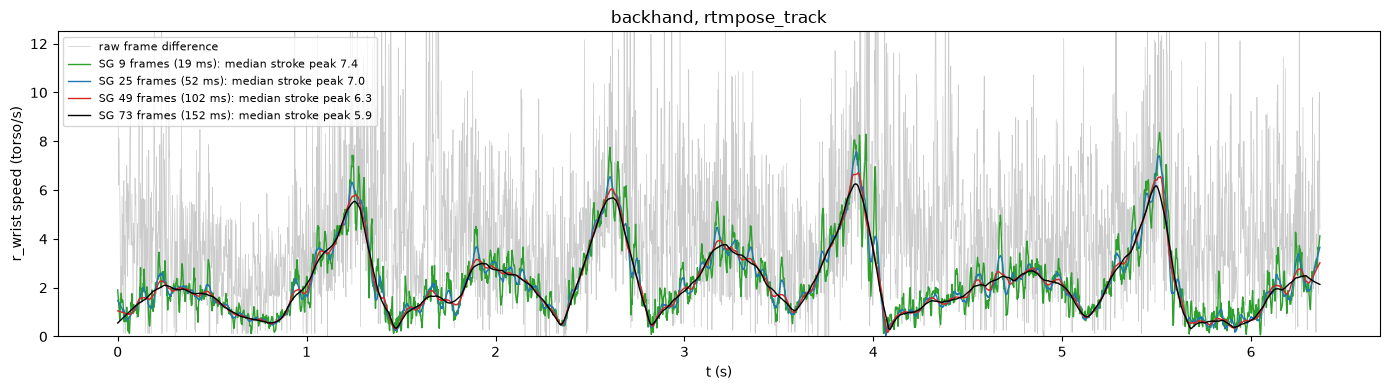

In [8]:
RTM = "rtmpose_track"
k = K["revesSM", RTM]; t = k["t"]; w = k["xy"][:, WR]
raw = np.linalg.norm(np.diff(w, axis=0), axis=1) / np.diff(t) / k["torso"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(t[1:], raw, color="0.8", lw=0.5, label="raw frame difference")
for win, col in [(9, "tab:green"), (25, "tab:blue"), (49, "tab:red"), (73, "k")]:
    s = speed(w, t, win) / k["torso"]
    pk, _ = detect_strokes(s, t)
    ax.plot(t, s, color=col, lw=1, label=f"SG {win} frames ({1000*win/480:.0f} ms): median stroke peak {np.median(s[pk]):.1f}")
ax.set_ylim(0, 2 * s.max()); ax.set_xlabel("t (s)"); ax.set_ylabel("r_wrist speed (torso/s)"); ax.legend(fontsize=8)
ax.set_title(f"backhand, {RTM}"); plt.tight_layout(); plt.show()

**Choice: SG, 25 frames (52 ms), order 2.** At 480 fps the raw frame difference is very noisy: the pixel jitter is similar to 60 fps, but dt is 8x shorter, so the speed noise is 8x larger. A 9-frame window (19 ms) is still ragged. 25 frames keeps the peak (7.0 torso/s) while removing the jitter. The 152 ms window, the same time span as the 60 fps analysis, gives 5.9: the time window, not only the frame rate, decides how much of the peak survives.

## 6. What does 60 fps lose? Same strokes, decimated
Take every 8th frame of the 480 fps keypoints (8 possible phases), so it is the same strokes sampled at 60 fps, then apply the 60 fps analysis (SG 9 frames). Compare the stroke peaks with the 480 fps analysis. This isolates sampling and filtering; it does not include the extra motion blur of a real 1/60 s exposure, so the real 60 fps loss is somewhat larger. The separate 60 fps takes from notebook 03 are listed for reference (different strokes, same movements).

In [9]:
WIN = 25
strokes60 = list(csv.DictReader(open(LOG / f"strokes_TableTennis1_60fps_{DATE}.csv")))
for c in ["revesSM"]:
    for m in ["mediapipe", RTM]:
        k = K[c, m]; t = k["t"]
        v480 = speed(k["xy"][:, WR], t, WIN) / k["torso"]
        pk480, _ = detect_strokes(v480, t)
        ratios = []
        for ph in range(8):
            t60, xy60 = t[ph::8], k["xy"][ph::8, WR]
            v60 = speed(xy60, t60, 9) / k["torso"]
            for p in pk480:  # 60 fps peak near each 480 fps peak (+-50 ms)
                near = np.abs(t60 - t[p]) < 0.05
                ratios.append(np.nanmax(v60[near]) / v480[p] if np.isfinite(v60[near]).any() else np.nan)
        ref = [float(r["v_peak"]) for r in strokes60 if r["stroke"] == CLIPS[c] and r["model"] == m.split("_")[0]]
        print(f"{CLIPS[c]:<9} {m:<14} 480 fps peak {np.median(v480[pk480]):4.1f} torso/s | decimated to 60 fps: "
              f"{100*np.nanmedian(ratios):3.0f} % of it (range {100*np.nanmin(ratios):3.0f}-{100*np.nanmax(ratios):3.0f} %) | "
              f"separate 60 fps take: {np.median(ref):4.1f}")

backhand  mediapipe      480 fps peak  8.1 torso/s | decimated to 60 fps:  79 % of it (range  73- 84 %) | separate 60 fps take:  8.0
backhand  rtmpose_track  480 fps peak  7.0 torso/s | decimated to 60 fps:  86 % of it (range  81- 89 %) | separate 60 fps take:  6.7


## 7. Strokes, per-stroke metrics, consistency
Metrics for the backhand only (forehand excluded, section 3). Same rules as notebook 03 (stroke = wrist-speed peak at least 0.6 s from a higher one, prominence 2 torso/s, height at least 60 % of the 99th percentile; elbow masked where a segment is shorter than 0.3 torso).

In [10]:
rows = []
for c in CLIPS:
    for m in ["mediapipe", RTM]:
        k = K[c, m]; t, xy, tor = k["t"], k["xy"], k["torso"]
        k["v"] = speed(xy[:, WR], t, WIN) / tor
        k["elbow"], short = elbow_series(xy, tor)
        k["short_frac"] = short.mean()
        k["peaks"], k["half"] = detect_strokes(k["v"], t)
        if c == "revesSM":  # forehand excluded (section 3)
            rows += [dict(clip=c, stroke=CLIPS[c], model=m, **r)
                     for r in stroke_metrics(t, xy, k["v"], k["elbow"], k["peaks"], k["half"], tor)]

cols = ["clip", "stroke", "model", "n", "t_peak", "v_peak", "elbow_at_peak", "elbow_min", "elbow_max", "path"]
with open(LOG / f"strokes_TableTennis1_480fps_{DATE}.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader()
    w.writerows({k: (f"{v:.3f}" if isinstance(v, float) else v) for k, v in r.items()} for r in rows)

print(f"{'stroke':<9} {'model':<14} {'#':>2} {'t_peak':>6} {'v_peak':>6} {'el@pk':>6} {'el_min':>6} {'el_max':>6} {'path':>5}")
for r in rows:
    print(f"{r['stroke']:<9} {r['model']:<14} {r['n']:2d} {r['t_peak']:6.2f} {r['v_peak']:6.1f} {r['elbow_at_peak']:6.1f} "
          f"{r['elbow_min']:6.1f} {r['elbow_max']:6.1f} {r['path']:5.2f}")
print("\nelbow masked (short segment):", {f"{c}/{m}": round(float(K[c, m]["short_frac"]), 2) for c in CLIPS for m in ["mediapipe", RTM]})

stroke    model           # t_peak v_peak  el@pk el_min el_max  path
backhand  mediapipe       1   1.29    8.2    nan   89.2  140.0  3.82
backhand  mediapipe       2   2.67    7.4    nan   66.6  179.8  4.39
backhand  mediapipe       3   3.94    8.0    nan   74.2  159.2  4.12
backhand  mediapipe       4   5.54    9.0    nan   62.8  145.5  3.73
backhand  rtmpose_track   1   1.24    6.3   91.7   89.9  135.8  5.96
backhand  rtmpose_track   2   2.61    6.6   75.9   72.1  137.5  6.07
backhand  rtmpose_track   3   3.91    7.6   77.2   76.3  140.3  6.25
backhand  rtmpose_track   4   5.51    7.4   67.1   67.1  145.9  6.11

elbow masked (short segment): {'derechasSM/mediapipe': 0.21, 'derechasSM/rtmpose_track': 0.29, 'revesSM/mediapipe': 0.36, 'revesSM/rtmpose_track': 0.46}


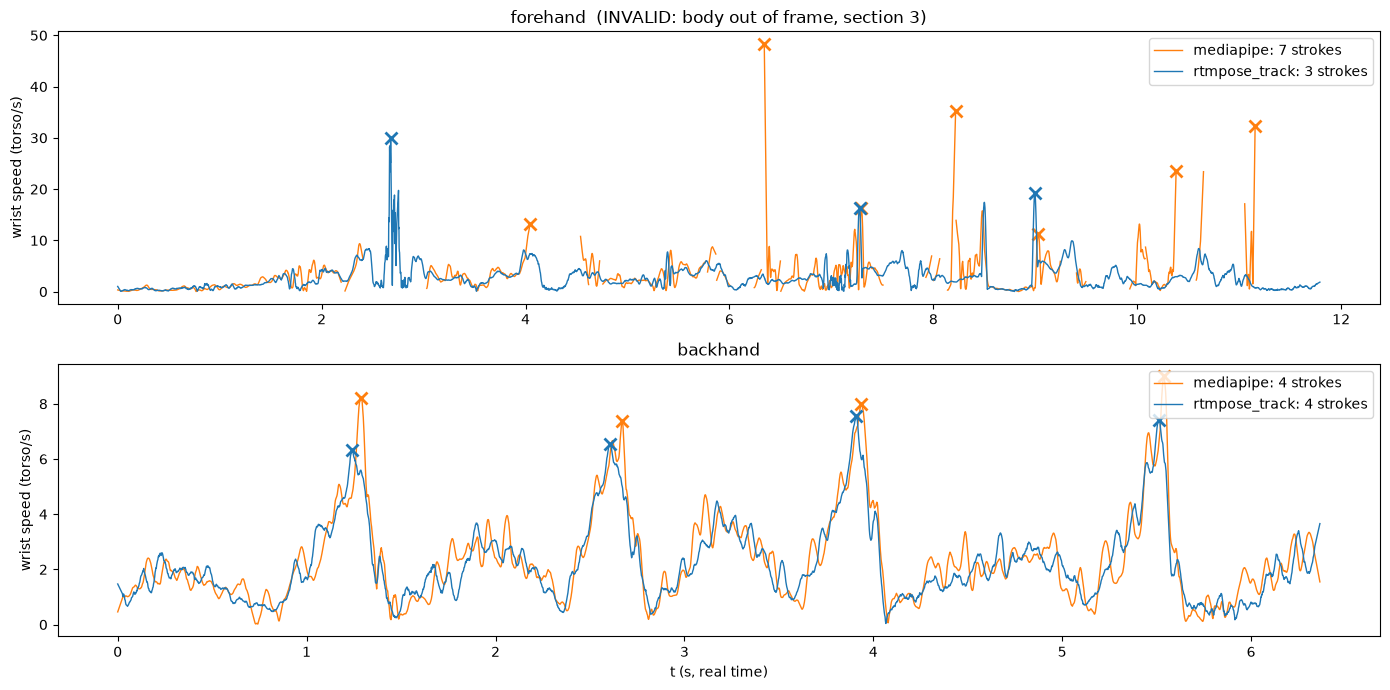

In [11]:
fig, axs = plt.subplots(2, 1, figsize=(14, 7))
for ax, c in zip(axs, CLIPS):
    for m, col in [("mediapipe", COL["mediapipe"]), (RTM, COL["rtmpose"])]:
        k = K[c, m]
        ax.plot(k["t"], k["v"], color=col, lw=1, label=f"{m}: {len(k['peaks'])} strokes")
        ax.plot(k["t"][k["peaks"]], k["v"][k["peaks"]], "x", color=col, ms=9, mew=2)
    ax.set_title(CLIPS[c] + ("  (INVALID: body out of frame, section 3)" if c == "derechasSM" else ""))
    ax.set_ylabel("wrist speed (torso/s)"); ax.legend(loc="upper right")
axs[-1].set_xlabel("t (s, real time)"); plt.tight_layout(); plt.show()

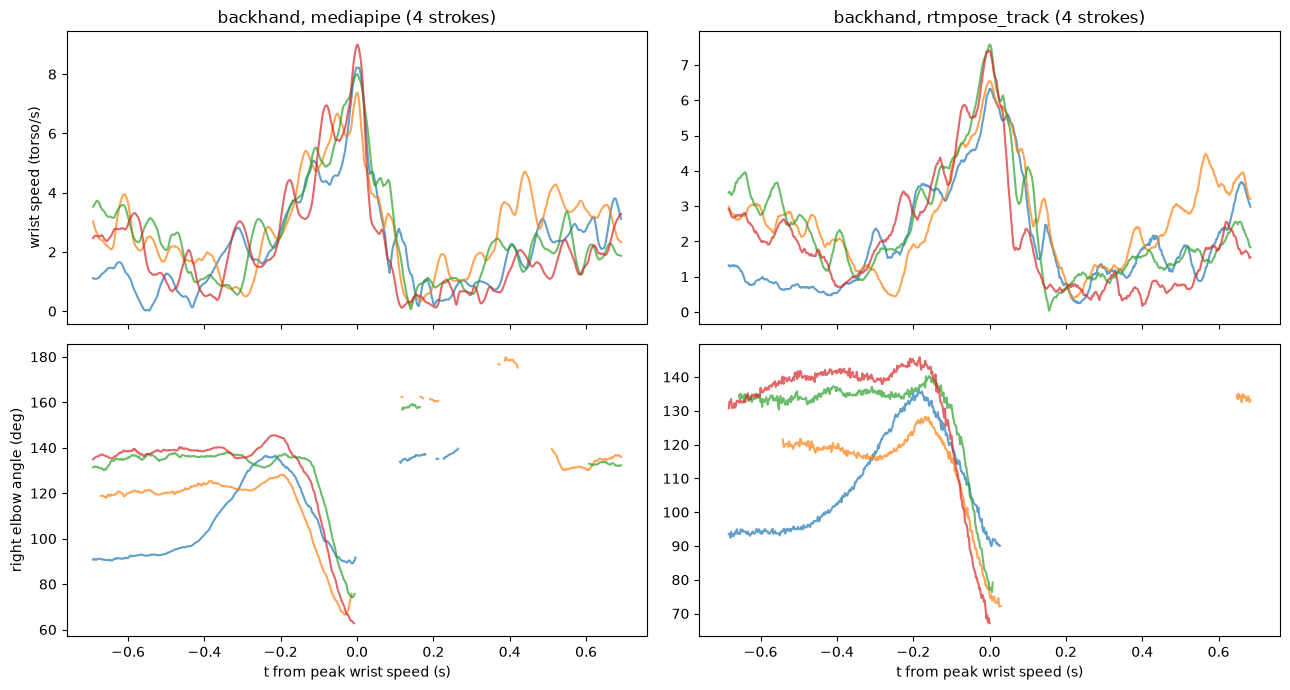

stroke    model           n        v_peak    elbow@peak  period s   elbow change at peak
backhand  mediapipe       4    8.2 +-  0.6    nan +-  nan      1.42          nan deg/frame
backhand  rtmpose_track   4    7.0 +-  0.5   78.0 +-  8.8      1.42         1.13 deg/frame


/tmp/ipykernel_74200/1745535670.py:17: RuntimeWarning: All-NaN slice encountered
  rate = np.nanmedian([abs(k["elbow"][p + 1] - k["elbow"][p - 1]) / 2 for p in k["peaks"]])
/tmp/ipykernel_74200/1745535670.py:19: RuntimeWarning: Mean of empty slice
  print(f"{CLIPS[c]:<9} {m:<14} {len(r):2d} {v.mean():6.1f} +- {v.std():4.1f} {np.nanmean(e):6.1f} +- {np.nanstd(e):4.1f} "
/home/sebas/HobbyProjects/pose-tracker/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1998: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [12]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for j, m in enumerate(["mediapipe", RTM]):
    k = K["revesSM", m]; t = k["t"]; h = k["half"]
    for p in k["peaks"]:
        lo, hi = max(0, p - h), min(len(t), p + h + 1)
        axs[0, j].plot(t[lo:hi] - t[p], k["v"][lo:hi], alpha=0.7)
        axs[1, j].plot(t[lo:hi] - t[p], k["elbow"][lo:hi], alpha=0.7)
    axs[0, j].set_title(f"backhand, {m} ({len(k['peaks'])} strokes)"); axs[1, j].set_xlabel("t from peak wrist speed (s)")
axs[0, 0].set_ylabel("wrist speed (torso/s)"); axs[1, 0].set_ylabel("right elbow angle (deg)")
plt.tight_layout(); plt.show()

print(f"{'stroke':<9} {'model':<14} {'n':>2} {'v_peak':>13} {'elbow@peak':>13} {'period s':>9} {'elbow change at peak':>22}")
for c in ["revesSM"]:
    for m in ["mediapipe", RTM]:
        r = [x for x in rows if x["clip"] == c and x["model"] == m]; k = K[c, m]
        v = np.array([x["v_peak"] for x in r]); e = np.array([x["elbow_at_peak"] for x in r])
        rate = np.nanmedian([abs(k["elbow"][p + 1] - k["elbow"][p - 1]) / 2 for p in k["peaks"]])
        per = np.diff([x["t_peak"] for x in r])
        print(f"{CLIPS[c]:<9} {m:<14} {len(r):2d} {v.mean():6.1f} +- {v.std():4.1f} {np.nanmean(e):6.1f} +- {np.nanstd(e):4.1f} "
              f"{per.mean():9.2f} {rate:12.2f} deg/frame")

## 8. Model agreement and motion blur
Backhand. Same as notebook 03: wrist gap between the models and wrist confidence against wrist speed. Below, crops around the paddle hand at peak speed: one 480 fps backhand stroke and one 60 fps backhand stroke (notebook 03 clip), to see the blur.

backhand  median all-joint gap  3.3 % | wrist gap: slow half  4.5 %, fastest 10 %  7.6 % | RTMPose wrist score slow 0.88, fast 0.89


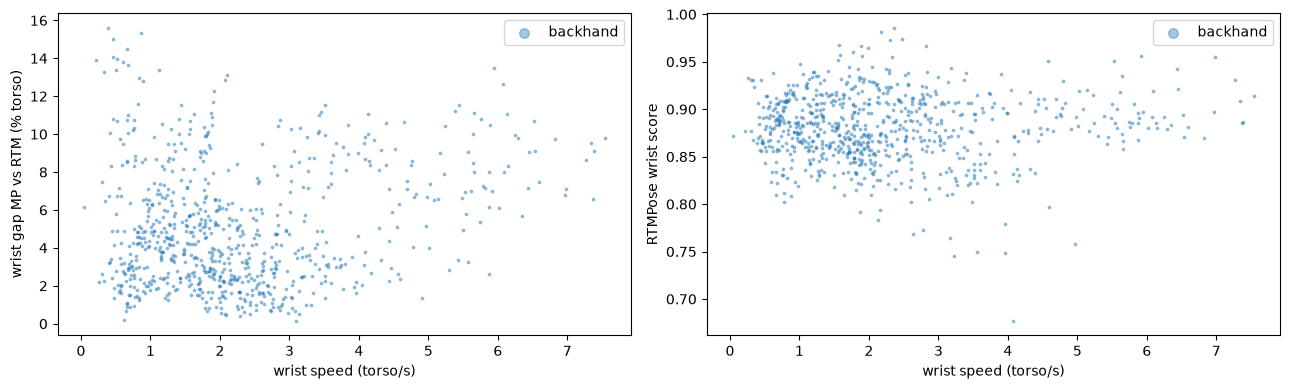

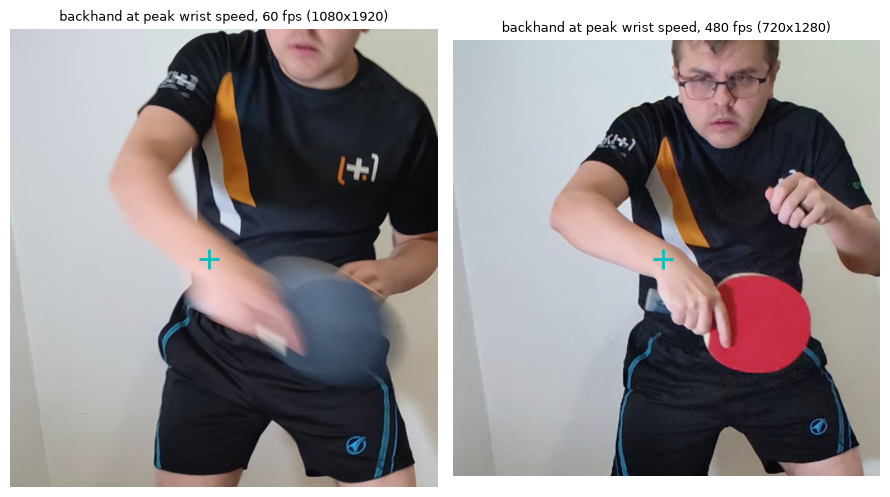

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for c in ["revesSM"]:
    a, b = K[c, "mediapipe"], K[c, RTM]
    d = 100 * np.linalg.norm(a["xy"] - b["xy"], axis=2) / b["torso"]; v = b["v"]
    fast, slow = v > np.nanpercentile(v, 90), v < np.nanpercentile(v, 50)
    axs[0].scatter(v[::4], d[::4, WR], s=3, alpha=0.4, label=CLIPS[c])
    axs[1].scatter(v[::4], b["conf"][::4, WR], s=3, alpha=0.4, label=CLIPS[c])
    print(f"{CLIPS[c]:<9} median all-joint gap {np.nanmedian(d):4.1f} % | wrist gap: slow half {np.nanmedian(d[slow, WR]):4.1f} %, "
          f"fastest 10 % {np.nanmedian(d[fast, WR]):4.1f} % | RTMPose wrist score slow {np.median(b['conf'][slow, WR]):.2f}, fast {np.median(b['conf'][fast, WR]):.2f}")
axs[0].set_ylabel("wrist gap MP vs RTM (% torso)"); axs[1].set_ylabel("RTMPose wrist score")
for ax in axs: ax.set_xlabel("wrist speed (torso/s)"); ax.legend(markerscale=4)
plt.tight_layout(); plt.show()

from pose_tracker.video import read_keypoints as rk
t60, xy60, _, _ = rk(DER / "reves60_keypoints_rtmpose.csv")
v60 = speed(xy60[:, WR], t60, 9); p60 = int(np.argmax(v60[: len(v60) // 2]))
k = K["revesSM", RTM]; p480 = int(k["peaks"][1])
fr60 = grab("reves60", [p60])[p60]; fr480 = grab("revesSM", [p480])[p480]
fig, axs = plt.subplots(1, 2, figsize=(9, 5))
for ax, fr, xy, tor, title in [(axs[0], fr60, xy60[p60], np.nanmedian([torso_px(f) for f in xy60]), "60 fps (1080x1920)"),
                               (axs[1], fr480, k["xy"][p480], k["torso"], "480 fps (720x1280)")]:
    cx, cy = xy[WR]; r = int(0.9 * tor)
    y0, x0 = max(0, int(cy) - r), max(0, int(cx) - r)
    ax.imshow(cv2.cvtColor(fr[y0:int(cy) + r, x0:int(cx) + r], cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.plot(cx - x0, cy - y0, "c+", ms=14, mew=2); ax.set_title(f"backhand at peak wrist speed, {title}", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Annotated videos
Both skeletons and a 0.1 s (48-frame) trail of the RTMPose wrist, written at 30 fps, i.e. 16x slow motion like the original file. H.264, standard range.

In [14]:
CV = {"mediapipe": (0, 140, 255), RTM: (200, 110, 30)}  # BGR
for c in CLIPS:
    out = DER / f"{c}_annotated.mp4"
    ff = subprocess.Popen(["ffmpeg", "-y", "-v", "error", "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{W}x{H}", "-r", "30",
                           "-i", "-", "-c:v", "libx264", "-crf", "22", "-pix_fmt", "yuv420p", str(out)], stdin=subprocess.PIPE)
    for i, fr in enumerate(iter_frames(VIDS / f"{c}.mp4")):
        for m, col in CV.items():
            if np.isnan(K[c, m]["xy"][i]).any(): continue
            pts = np.round(K[c, m]["xy"][i]).astype(int)
            for a, b in EDGES:
                cv2.line(fr, tuple(pts[a]), tuple(pts[b]), col, 2, cv2.LINE_AA)
        tr = np.round(K[c, RTM]["xy"][max(0, i - 48):i + 1, WR]).astype(np.int32)
        cv2.polylines(fr, [tr], False, (0, 255, 0), 2, cv2.LINE_AA)
        cv2.putText(fr, f"{CLIPS[c]} t={T[c][i]:.3f}s " + (f" v={K[c, RTM]['v'][i]:.1f} torso/s" if c == "revesSM" else " (body out of frame)"), (12, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 2, cv2.LINE_AA)
        ff.stdin.write(fr.tobytes())
    ff.stdin.close(); ff.wait()
    print(out.relative_to(ROOT), f"{out.stat().st_size/1e6:.1f} MB")

data/derived/TableTennis1/vids/derechasSM_annotated.mp4 48.0 MB


data/derived/TableTennis1/vids/revesSM_annotated.mp4 36.9 MB


## Takeaways
## Takeaways (2026-11-18; analysis on the backhand clip only, see section 3)
- **The 480 fps is real capture** (strong evidence, not proof). The room light flickers at 120 Hz, and the frames catch four independent brightness levels per cycle, which interpolation cannot produce. Side effect: brightness swings by about ±3 grey levels with a 4-frame period. Any colour or difference method (the paddle mask) must normalize brightness per frame. Pixel noise is higher than at 60 fps (shorter exposure).
- **Framing decides everything.** The 720p slow-motion view is tighter. In the backhand clip you are in frame, except the left ankle (about 60 % of frames at the edge). In the forehand clip you stand at the right edge: the torso, hips and legs are out of frame most of the time. The skeleton collapses onto the frame edge, MediaPipe loses you in 23 % of frames, and speeds come out at 20-48 torso/s. **The forehand slow-motion clip is not usable** for pose metrics; re-record it with the whole body in frame.
- **RTMPose cost:** running the detector only on the first frame and letting the box follow the skeleton gives the same keypoints as running it on every frame (within about 1 % of torso length), at 28-31 ms instead of 379 ms per frame. The full backhand clip takes 1.5 min instead of 19 min. MediaPipe takes 21 ms per frame.
- **Backhand at 480 fps:** 4 strokes, found by both models (peak times within 0.06 s), period 1.42 s. Peak wrist speed 7.0 ± 0.5 torso/s (RTMPose) and 8.2 ± 0.6 (MediaPipe), with SG 52 ms. MediaPipe again reads about 1 torso/s higher than RTMPose: a model offset, as at 60 fps.
- **What 60 fps loses:** the same strokes, decimated to 60 fps and analyzed as in notebook 03, keep 86 % (RTMPose, range 81-89 %) and 79 % (MediaPipe) of the 480 fps peak. Most of the loss comes from the 150 ms time window that 60 fps needs. The separate 60 fps backhand take measured 6.7 torso/s vs 7.0 here, consistent with that.
- **Elbow angle at peak** now changes about 1.1 deg per frame (about 10 deg per frame at 60 fps), so timing no longer dominates the metric: 78 ± 9 deg over 4 strokes (RTMPose). Still, 46 % of frames are masked as foreshortened in this front view, and MediaPipe's elbow is masked at every peak. A side view is still needed for the elbow.
- **Blur:** at peak speed the paddle is a smear at 60 fps and sharp at 480 fps (crops in section 8). The RTMPose wrist score no longer drops with speed (0.88 slow, 0.89 fast; at 60 fps 0.88 to 0.81). The model gap at the wrist in the fastest frames is 7.6 % of torso vs 10.2 % at 60 fps.
- **Wrist path length is not comparable across frame rates:** it sums per-frame steps, so keypoint jitter adds up (RTMPose 6.0-6.3 torso lengths per stroke here vs 3.2-3.9 at 60 fps). It needs smoothed positions: the filtering stage.
- **Next:** re-record the slow-motion forehand (and a side view of both strokes) with the whole body in frame and 10+ strokes. Then the filtering stage, then the paddle (now sharp at 480 fps, so the colour mask near the hand has a chance).